# Data Mining Lab – Assignment 2
## Book Recommender System built on a Medallion Data Lake

**Name:** Akhand Pratap Dhiryan  **Roll No:** LCI2023022

**Dataset:** Book-Crossing (`BX-Users`, `BX-Books`, `BX-Book-Ratings`)

| Layer | Folder | What it holds |
|---|---|---|
| Bronze | `bronze/` | the three source files exactly as delivered, plus `ingestion_timestamp` |
| Silver | `silver/` | cleaned, de-duplicated, validated tables |
| Gold | `gold/` | sparse user–book matrix, book lookup, user/book aggregates |

The recommender is **item-based collaborative filtering** with cosine similarity between books. Two variants — plain cosine on the
raw ratings and adjusted (mean-centred) cosine — are compared with a leave-one-out test, and the better one is used (Step 5.5).

In [1]:
import os
import re
import html
import zipfile
import urllib.request
from collections import defaultdict
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 25)
pd.set_option("display.max_colwidth", 65)

## Step 1 – Data lake folders and the Bronze layer

In [2]:
LAKE = {layer: layer for layer in ("raw", "bronze", "silver", "gold")}
for folder in LAKE.values():
    os.makedirs(folder, exist_ok=True)

SOURCE_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
ZIP_FILE = os.path.join(LAKE["raw"], "book-crossings.zip")

if not os.path.exists(ZIP_FILE):
    # the CDN answers 403 to Python's default User-Agent
    request = urllib.request.Request(SOURCE_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as response:
        with open(ZIP_FILE, "wb") as out:
            out.write(response.read())

with zipfile.ZipFile(ZIP_FILE) as archive:
    archive.extractall(LAKE["raw"])
    print("files in archive:", archive.namelist())

files in archive: ['BX-Book-Ratings.csv', 'BX-Books.csv', 'BX-Users.csv']


**Reading the raw files.** They are `;`-separated and encoded as ISO-8859-1 (latin-1). Some titles contain
quotes escaped with a backslash (`\"`); if `escapechar` is not set, pandas mis-parses those lines and loses book rows.
Nothing else is changed — Bronze must stay a faithful copy of the source.

In [3]:
CSV_OPTIONS = {"sep": ";", "encoding": "latin-1", "escapechar": "\\", "low_memory": False}
SOURCES = {
    "users":   "raw/BX-Users.csv",
    "books":   "raw/BX-Books.csv",
    "ratings": "raw/BX-Book-Ratings.csv",
}

loaded_at = pd.Timestamp.now(tz=timezone.utc)
bronze = {}
for table, csv_path in SOURCES.items():
    frame = pd.read_csv(csv_path, **CSV_OPTIONS)
    frame["ingestion_timestamp"] = loaded_at
    frame.to_parquet(f"bronze/{table}.parquet", index=False)
    bronze[table] = frame
    print(f"bronze/{table}.parquet <- {csv_path:26s} rows={len(frame):>9,}  cols={frame.shape[1]}")

bronze/users.parquet <- raw/BX-Users.csv           rows=  278,858  cols=4


bronze/books.parquet <- raw/BX-Books.csv           rows=  271,379  cols=9


bronze/ratings.parquet <- raw/BX-Book-Ratings.csv    rows=1,149,780  cols=4


In [4]:
# Did every record make it into Bronze?  Compare with the raw line count of each file.
check = []
for table, csv_path in SOURCES.items():
    with open(csv_path, encoding="latin-1") as fh:
        data_lines = sum(1 for _ in fh) - 1
    check.append({"table": table, "lines_in_csv": data_lines,
                  "rows_in_bronze": len(pd.read_parquet(f"bronze/{table}.parquet"))})
pd.DataFrame(check)

,table,lines_in_csv,rows_in_bronze
0,users,278859,278858
1,books,271379,271379
2,ratings,1149780,1149780


Books and ratings match exactly. Users shows one extra *line* because a single location value has a newline inside its
quotes, so one record is spread over two lines — the record count itself is complete.

## Step 2 – Exploratory analysis of Bronze

In [5]:
users_raw = pd.read_parquet("bronze/users.parquet")
books_raw = pd.read_parquet("bronze/books.parquet")
ratings_raw = pd.read_parquet("bronze/ratings.parquet")

overview = []
for table, frame in (("users", users_raw), ("books", books_raw), ("ratings", ratings_raw)):
    for column in frame.columns:
        overview.append({"table": table, "rows": len(frame), "column": column,
                         "dtype": str(frame[column].dtype), "nulls": int(frame[column].isna().sum())})
pd.DataFrame(overview).set_index(["table", "rows", "column"])

dtype   nulls
table   rows    column                                          
users   278858  User-ID                            int64       0
                Location                             str       0
                Age                              float64  110762
                ingestion_timestamp  datetime64[us, UTC]       0
books   271379  ISBN                                 str       0
                Book-Title                           str       0
                Book-Author                          str       2
                Year-Of-Publication                int64       0
                Publisher                            str       2
                Image-URL-S                          str       0
                Image-URL-M                          str       0
                Image-URL-L                          str       0
                ingestion_timestamp  datetime64[us, UTC]       0
ratings 1149780 User-ID                            int64       0
                ISBN                                 str       0
                Book-Rating                        int64       0
                ingestion_timestamp  datetime64[us, UTC]       0

In [6]:
quality = {
    "duplicate rows (users)":            users_raw.drop(columns="ingestion_timestamp").duplicated().sum(),
    "duplicate User-ID":                 users_raw["User-ID"].duplicated().sum(),
    "duplicate rows (books)":            books_raw.drop(columns="ingestion_timestamp").duplicated().sum(),
    "duplicate ISBN (as given)":         books_raw["ISBN"].duplicated().sum(),
    "duplicate ISBN (trimmed + upper)":  books_raw["ISBN"].str.strip().str.upper().duplicated().sum(),
    "duplicate (User-ID, ISBN)":         ratings_raw.duplicated(["User-ID", "ISBN"]).sum(),
    "ratings with unknown ISBN":         (~ratings_raw["ISBN"].isin(books_raw["ISBN"])).sum(),
    "ratings with unknown User-ID":      (~ratings_raw["User-ID"].isin(users_raw["User-ID"])).sum(),
    "titles with HTML entities":         books_raw["Book-Title"].str.contains(r"&[a-zA-Z]+;|&#\d+;").sum(),
    "titles with extra whitespace":      books_raw["Book-Title"].str.contains(r"^\s|\s$|\s\s").sum(),
}
pd.Series(quality, name="count").to_frame()

,count
duplicate rows (users),0
duplicate User-ID,0
duplicate rows (books),0
duplicate ISBN (as given),0
duplicate ISBN (trimmed + upper),315
"duplicate (User-ID, ISBN)",0
ratings with unknown ISBN,118605
ratings with unknown User-ID,0
titles with HTML entities,4908
titles with extra whitespace,2505


**Finding 1 – shape, types, missing values.** Users 278,858 × 3, Books 271,379 × 8, Ratings 1,149,780 × 3 (plus the timestamp).
`Age` is null for ~40% of users (110,762); `Book-Author` and `Publisher` are null in 2 rows each; ratings have no nulls.
No row is an exact duplicate, but 315 ISBNs collide once the `x`/`X` check digit is upper-cased, 118,605 ratings point to
books that are not in the books table, and thousands of titles carry HTML entities or stray spaces.
**Silver action:** snake_case column names, upper-case + de-duplicate ISBNs, decode entities / trim spaces, and drop ratings without a matching book or user.

Book-Rating      0     1     2     3     4      5      6      7       8      9      10
ratings      716109  1770  2759  5996  8904  50974  36924  76457  103736  67541  78610

rating == 0 : 716,109 rows  (62.3% of all ratings)


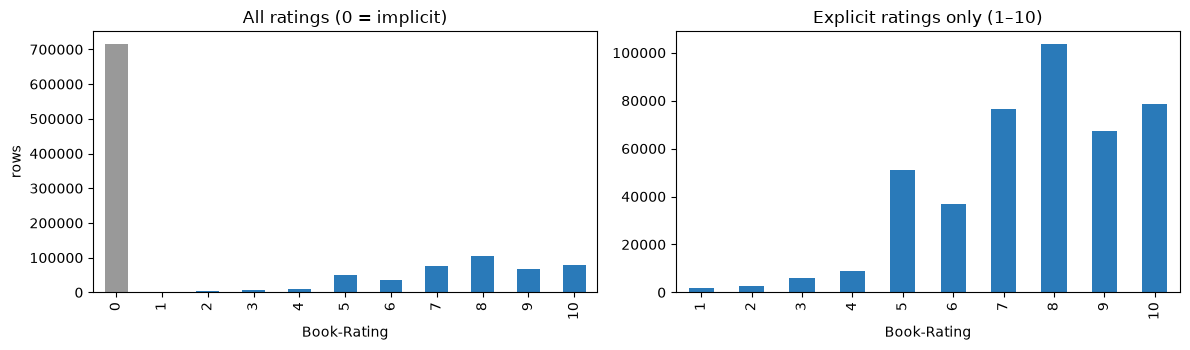

In [7]:
score_counts = ratings_raw["Book-Rating"].value_counts().sort_index()
zero_share = score_counts.loc[0] / score_counts.sum()
print(score_counts.rename("ratings").to_frame().T.to_string())
print(f"\nrating == 0 : {score_counts.loc[0]:,} rows  ({zero_share:.1%} of all ratings)")

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.6))
score_counts.plot.bar(ax=left, color=["#999999"] + ["#2a7ab9"] * 10)
left.set_title("All ratings (0 = implicit)"); left.set_xlabel("Book-Rating"); left.set_ylabel("rows")
score_counts.drop(0).plot.bar(ax=right, color="#2a7ab9")
right.set_title("Explicit ratings only (1–10)"); right.set_xlabel("Book-Rating")
plt.tight_layout(); plt.show()

**Finding 2 – rating distribution.** 716,109 rows (62.3%) have rating 0, which in Book-Crossing means "interacted, did not rate".
The explicit scores are skewed upwards: the mode is 8, and 1–4 are rare.
**Silver action:** drop the zeros and keep only 1–10. The upward skew also means raw ratings mostly say "liked it"; that is why the
recommender also tries mean-centring each user's ratings (adjusted cosine, Step 5).

value
Age                 min                  0.0
                    median              32.0
                    max                244.0
                    missing         110762.0
                    < 5                882.0
                    > 100              366.0
Year-Of-Publication min (non-zero)    1376.0
                    median            1995.0
                    max               2050.0
                    == 0              4619.0
                    > 2026              11.0

future years present: [np.int64(2030), np.int64(2037), np.int64(2038), np.int64(2050)]

very old titles (year < 1500):


,ISBN,Book-Title,Year-Of-Publication
227544,9643112136,Dalan-i bihisht (Dastan-i Irani),1378
253767,964442011X,Tasht-i khun,1376


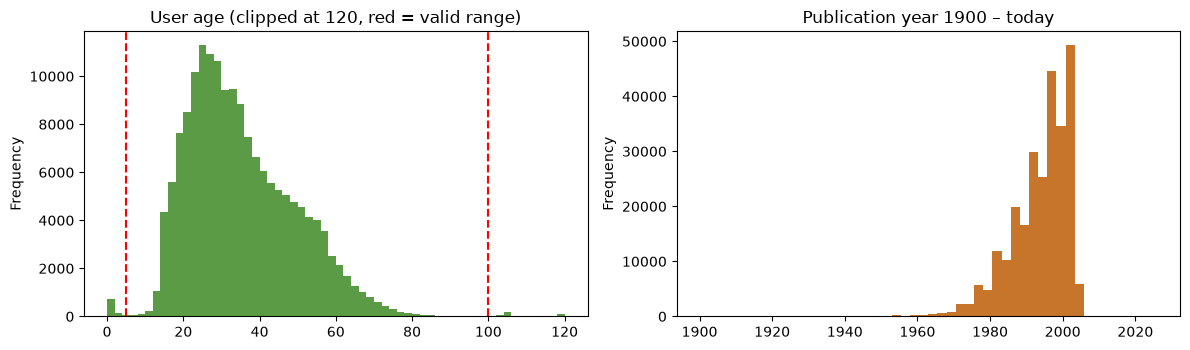

In [8]:
age = users_raw["Age"]
pub_year = books_raw["Year-Of-Publication"]
this_year = datetime.now().year

age_report = pd.Series({
    "min": age.min(), "median": age.median(), "max": age.max(),
    "missing": age.isna().sum(), "< 5": (age < 5).sum(), "> 100": (age > 100).sum()})
year_report = pd.Series({
    "min (non-zero)": pub_year[pub_year > 0].min(), "median": pub_year.median(), "max": pub_year.max(),
    "== 0": (pub_year == 0).sum(), f"> {this_year}": (pub_year > this_year).sum()})
display(pd.concat({"Age": age_report, "Year-Of-Publication": year_report}).to_frame("value"))
print("future years present:", sorted(pub_year[pub_year > this_year].unique()))
print("\nvery old titles (year < 1500):")
display(books_raw.loc[pub_year.between(1, 1499), ["ISBN", "Book-Title", "Year-Of-Publication"]])

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.6))
age.dropna().clip(upper=120).plot.hist(bins=60, ax=left, color="#5b9b45")
left.axvline(5, color="red", ls="--"); left.axvline(100, color="red", ls="--")
left.set_title("User age (clipped at 120, red = valid range)")
pub_year[pub_year.between(1900, this_year)].plot.hist(bins=50, ax=right, color="#c7752b")
right.set_title("Publication year 1900 – today")
plt.tight_layout(); plt.show()

**Finding 3 – ages and publication years.** Age runs from 0 to 244; 882 users are under 5 and 366 are over 100, which are not
realistic. Publication year is 0 for 4,619 books and lies in the future for 11 (2030 … 2050). The two titles from 1376/1378 have
ISBN prefix 964 (Iran) and use the Solar Hijri calendar, so they are kept.
**Silver action:** ages outside 5–100 → null, then median fill; year 0 or later than the current year → null.

,per user,per book
count,77805.00,185973.00
mean,5.57,2.33
std,44.00,6.83
min,1.00,1.00
50%,1.00,1.00
75%,3.00,2.00
90%,9.00,4.00
99%,73.00,22.00
max,8524.00,707.00


users: only 1 rating = 58.3% | with >= 5 = 14,220 | >= 10 = 7,334 | >= 20 = 3,704
books: only 1 rating = 69.7% | with >= 5 = 14,535 | >= 10 = 5,645 | >= 20 = 2,179


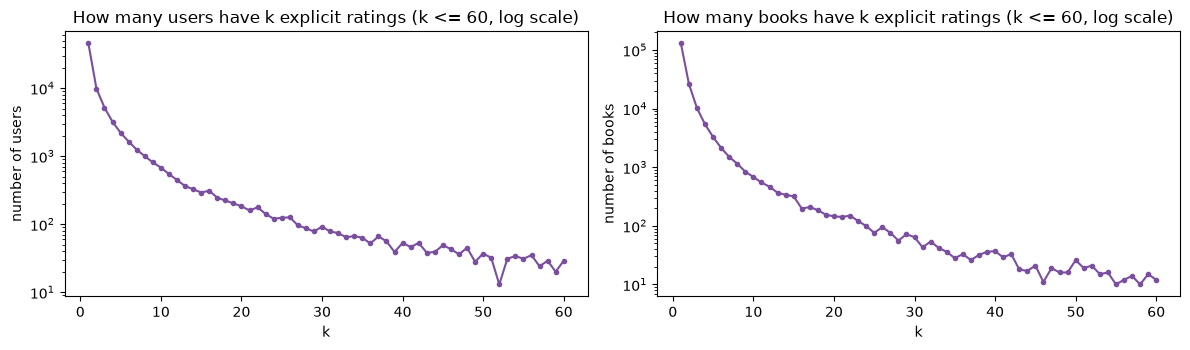

In [9]:
explicit = ratings_raw[ratings_raw["Book-Rating"] > 0]
activity = pd.DataFrame({
    "per user": explicit.groupby("User-ID").size().describe(percentiles=[.5, .75, .9, .99]),
    "per book": explicit.groupby("ISBN").size().describe(percentiles=[.5, .75, .9, .99]),
}).round(2)
display(activity)

for label, counts in (("users", explicit.groupby("User-ID").size()), ("books", explicit.groupby("ISBN").size())):
    print(f"{label}: only 1 rating = {(counts == 1).mean():.1%} | with >= 5 = {(counts >= 5).sum():,} "
          f"| >= 10 = {(counts >= 10).sum():,} | >= 20 = {(counts >= 20).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, (label, key) in zip(axes, (("user", "User-ID"), ("book", "ISBN"))):
    counts = explicit.groupby(key).size()
    counts.value_counts().sort_index().loc[:60].plot(ax=ax, logy=True, marker=".", color="#7b4fa0")
    ax.set_title(f"How many {label}s have k explicit ratings (k <= 60, log scale)")
    ax.set_xlabel("k"); ax.set_ylabel(f"number of {label}s")
plt.tight_layout(); plt.show()

**Finding 4 – ratings per user and per book.** Both are extremely long-tailed: the median user and the median book have exactly
one explicit rating (58.3% of users and 69.7% of books have just one), while one user has rated over a thousand books.
**Silver action:** apply a minimum-activity filter on users and books, because a book with one rating shares no raters with other books and its similarity is meaningless.

In [10]:
def fill_rate(frame, user_col="User-ID", item_col="ISBN"):
    n_users, n_items = frame[user_col].nunique(), frame[item_col].nunique()
    return n_users, n_items, len(frame) / (n_users * n_items)

rows = []
for label, frame in (("all ratings (incl. 0)", ratings_raw), ("explicit ratings 1-10", explicit)):
    n_users, n_items, filled = fill_rate(frame)
    rows.append({"subset": label, "users": n_users, "books": n_items, "cells": n_users * n_items,
                 "ratings": len(frame), "filled_%": round(100 * filled, 5), "sparsity_%": round(100 * (1 - filled), 5)})
pd.DataFrame(rows).set_index("subset")

,users,books,cells,ratings,filled_%,sparsity_%
subset,,,,,,
all ratings (incl. 0),105283,340556,35854757348,1149780,0.00321,99.99679
explicit ratings 1-10,77805,185973,14469629265,433671,0.00300,99.99700


**Finding 5 – sparsity.** Out of ≈35.9 billion possible user–book cells only 0.0032% hold a rating (0.0030% for explicit ratings),
i.e. the matrix is 99.997% empty.
**Silver/Gold action:** the activity filter will make it much denser, and the matrix is stored in sparse CSR format instead of a dense array.

## Step 3 – Cleaning: the Silver layer
Every step records the row counts so the effect of each rule is visible at the end.

In [11]:
SHORT_NAMES = {"book_title": "title", "book_author": "author", "year_of_publication": "year", "book_rating": "rating"}

def to_silver_names(frame):
    # "Book-Title" -> "book_title" -> "title";  the Bronze-only timestamp column is not carried over
    snake = {c: c.lower().replace("-", "_") for c in frame.columns}
    return (frame.drop(columns="ingestion_timestamp")
                 .rename(columns=snake)
                 .rename(columns=SHORT_NAMES))

users, books, ratings = (to_silver_names(t) for t in (users_raw, books_raw, ratings_raw))
print({name: list(t.columns) for name, t in (("users", users), ("books", books), ("ratings", ratings))})

audit = []
def record(step):
    audit.append({"step": step, "users": len(users), "books": len(books), "ratings": len(ratings)})

record("loaded from bronze")

{'users': ['user_id', 'location', 'age'], 'books': ['isbn', 'title', 'author', 'year', 'publisher', 'image_url_s', 'image_url_m', 'image_url_l'], 'ratings': ['user_id', 'isbn', 'rating']}


### 3.1 Text columns
* drop the three image-URL columns (not used by the recommender);
* decode HTML entities (`&amp;` → `&`), collapse repeated whitespace and trim;
* repair "mojibake" — UTF-8 text that was saved as latin-1 (`ExupÃ©ry` → `Exupéry`). Some values were broken twice and one byte
  became `?` (`KÃ?Â¤stner`); the remaining continuation byte still tells which letter it was, so it is rebuilt;
* standardise case: ISBN upper case, title/author/publisher Title Case, location lower case;
* normalise author initials so that `J.R.R. Tolkien` and `J. R. R. Tolkien` are the same author.

In [12]:
DOUBLE_BROKEN = re.compile(r"Ã\?Â([\x80-\xbf])")
TITLE_START = re.compile(r"(?<![\w'])[^\W\d_]")   # first letter of a word, not after an apostrophe or a digit

def repair_encoding(value):
    if "Ã" not in value and "Â" not in value:
        return value
    value = DOUBLE_BROKEN.sub(lambda m: bytes([0xC3, ord(m.group(1))]).decode("utf-8"), value)
    try:
        return value.encode("latin-1").decode("utf-8")
    except UnicodeError:
        return value

def tidy(series):
    out = series.astype("string").map(lambda v: repair_encoding(html.unescape(v)) if isinstance(v, str) else v)
    out = out.str.replace(r"\s+", " ", regex=True).str.strip()
    return out.replace("", pd.NA)

def title_case(series):
    # lower everything, then capitalise word starts; "sorcerer's" and "1st" are left alone
    return series.str.lower().str.replace(TITLE_START, lambda m: m.group(0).upper(), regex=True)

books = books.drop(columns=books.columns[books.columns.str.startswith("image_url")])
books["isbn"] = tidy(books["isbn"]).str.upper()
books["title"] = title_case(tidy(books["title"]))
books["publisher"] = title_case(tidy(books["publisher"]))
books["author"] = title_case(tidy(books["author"])).str.replace(r"\.(?=\w)", ". ", regex=True)
ratings["isbn"] = tidy(ratings["isbn"]).str.upper()
users["location"] = tidy(users["location"]).str.lower()

def broken(frame, cols):
    return int(sum(frame[c].str.contains("Ã|Â", na=False).sum() for c in cols))

print("distinct authors :", books_raw["Book-Author"].nunique(), "->", books["author"].nunique())
print("mojibake values  :", broken(books_raw, ["Book-Title", "Book-Author", "Publisher"]), "->",
      broken(books, ["title", "author", "publisher"]), "(the rest lost bytes and cannot be rebuilt)")
books.sample(6, random_state=7)

distinct authors : 102026 -> 98459
mojibake values  : 10516 -> 657 (the rest lost bytes and cannot be rebuilt)


,isbn,title,author,year,publisher
52951,0758203381,The Secret Life Of Bryan,Lori Foster,2004,Brava
18172,0373162510,Honeymoon Hotel,Barbara Bretton,1988,Harlequin
185706,0595206425,My Brother's Keeper,Lorrieann Russell,2001,Writers Club Press
159840,0679740309,Maiden Voyages: Writings Of Women Travelers (Vintage Departures),Mary Morris,1993,Vintage Books Usa
228799,0517571072,Parent Power: A Program To Help Your Child Succeed In School,Sherry Ferguson,1989,Random House Inc
217249,0812544676,The Randolph Legacy,Eileen Charbonneau,1998,Tor Books (Mm)


### 3.2 Duplicates
Exact duplicates first, then one row per key: `user_id`, `isbn` (the collisions created by upper-casing the ISBN) and `(user_id, isbn)`.

In [13]:
users = users.drop_duplicates().drop_duplicates("user_id")
books = books.drop_duplicates().drop_duplicates("isbn")
ratings = ratings.drop_duplicates().drop_duplicates(["user_id", "isbn"], keep="last")
record("duplicates removed")
pd.DataFrame(audit).set_index("step").diff().iloc[1:].abs().rename(index=lambda s: f"removed by: {s}")

,users,books,ratings
step,,,
removed by: duplicates removed,0.0,315.0,0.0


### 3.3 Explicit ratings only

In [14]:
ratings = ratings[ratings["rating"].between(1, 10)]
record("rating 0 removed")
print(f"explicit ratings kept: {len(ratings):,}   range: {ratings['rating'].min()}–{ratings['rating'].max()}")

explicit ratings kept: 433,671   range: 1–10


### 3.4 Ages
Values below 5 or above 100 become null, and all nulls are filled with the median of the valid ages.

In [15]:
out_of_range = ~users["age"].between(5, 100) & users["age"].notna()
users.loc[out_of_range, "age"] = np.nan
fill_value = users["age"].median()
print(f"ages made null: {out_of_range.sum():,} | nulls filled with median {fill_value:.0f}: {users['age'].isna().sum():,}")
users["age"] = users["age"].fillna(fill_value).astype("int16")
users["age"].describe().to_frame().T

ages made null: 1,248 | nulls filled with median 32: 112,010


,count,mean,std,min,25%,50%,75%,max
age,278858.0,33.643385,10.630979,5.0,29.0,32.0,35.0,100.0


### 3.5 Location → city / state / country
Rule: the first comma-separated part is the city, the last part is the country, anything in between is the state.
A location with only two parts is treated as `city, country`. Placeholder parts (`n/a`, `?`, empty, …) become null.

In [16]:
PLACEHOLDER_WORDS = {"n/a", "na", "none", "null", "unknown", "xxx"}

def as_place(part):
    # a usable place name has at least two letters and is not a filler word
    part = part.strip()
    if len(re.findall(r"[^\W\d_]", part)) < 2 or part.replace(".", "") in PLACEHOLDER_WORDS:
        return None
    return part

def parse_location(text):
    if not isinstance(text, str):
        return None, None, None
    parts = [as_place(p) for p in text.split(",")]
    city = parts[0]
    country = parts[-1] if len(parts) > 1 else None
    middle = [p for p in parts[1:-1] if p]
    return city, (", ".join(middle) or None), country

parsed = pd.DataFrame(users["location"].map(parse_location).tolist(),
                      columns=["city", "state", "country"], index=users.index)
users = users.join(parsed)

print("nulls:", users[["city", "state", "country"]].isna().sum().to_dict())
display(users["country"].value_counts().head(8).to_frame("users").T)
users.sample(5, random_state=3)

nulls: {'city': 887, 'state': 16620, 'country': 4627}


country,usa,canada,united kingdom,germany,spain,australia,italy,france
users,139712,21658,18556,17073,13258,11785,11271,3487


,user_id,location,age,city,state,country
92540,92541,"ba, buenos aires, argentina",22,ba,buenos aires,argentina
85848,85849,"stockholm, stockholm, sweden",32,stockholm,stockholm,sweden
88297,88298,"newhall, california, usa",32,newhall,california,usa
88534,88535,"durango, colorado, usa",32,durango,colorado,usa
44477,44478,"elliston, newfoundland, canada",45,elliston,newfoundland,canada


### 3.6 Publication year
Year 0 and years after the current year become null. The nullable `Int64` type keeps the column integer.

In [17]:
invalid_year = books["year"].eq(0) | books["year"].gt(this_year)
print(f"years made null: {invalid_year.sum():,}")
books["year"] = books["year"].astype("Int64").mask(invalid_year)
print("remaining range:", books["year"].min(), "to", books["year"].max())

years made null: 4,623
remaining range: 1376 to 2026


### 3.7 Referential integrity

In [18]:
known = ratings["isbn"].isin(books["isbn"]) & ratings["user_id"].isin(users["user_id"])
print(f"ratings dropped (book or user not found): {(~known).sum():,}")
ratings = ratings[known]
record("orphans removed")
print(f"{len(ratings):,} ratings from {ratings['user_id'].nunique():,} users on {ratings['isbn'].nunique():,} books")

ratings dropped (book or user not found): 49,818
383,853 ratings from 68,092 users on 149,723 books


### 3.8 Minimum activity threshold
Dropping inactive users can make some books fall below the limit and vice versa, so the filter is applied repeatedly until
the data stops changing (a "k-core"). Candidate thresholds:

In [19]:
def k_core(frame, min_per_user, min_per_book):
    previous = None
    while previous != len(frame):
        previous = len(frame)
        per_user = frame["user_id"].value_counts()
        frame = frame[frame["user_id"].isin(per_user.index[per_user >= min_per_user])]
        per_book = frame["isbn"].value_counts()
        frame = frame[frame["isbn"].isin(per_book.index[per_book >= min_per_book])]
    return frame

options = []
for mu, mb in [(1, 1), (3, 5), (5, 5), (5, 10), (10, 10), (10, 15)]:
    core = k_core(ratings, mu, mb)
    nu, nb = core["user_id"].nunique(), core["isbn"].nunique()
    options.append({"min/user": mu, "min/book": mb, "ratings": len(core), "users": nu, "books": nb,
                    "density_%": round(100 * len(core) / max(nu * nb, 1), 4),
                    "median ratings/user": core.groupby("user_id").size().median(),
                    "median ratings/book": core.groupby("isbn").size().median()})
pd.DataFrame(options)

,min/user,min/book,ratings,users,books,density_%,median ratings/user,median ratings/book
0,1,1,383853,68092,149723,0.0038,1.0,1.0
1,3,5,138547,12085,10534,0.1088,5.0,8.0
2,5,5,115332,6858,9092,0.1850,9.0,8.0
3,5,10,69346,4749,3060,0.4772,9.0,16.0
4,10,10,41469,1820,2030,1.1224,16.0,15.0
5,10,15,18839,969,709,2.7421,15.0,21.0


**Chosen threshold: a user needs ≥ 5 ratings and a book needs ≥ 10 ratings.**

* **Books get the stricter limit** because item-based CF compares *book* vectors. Finding 4 showed that ~70% of books have a single
  rating — such a vector can only overlap with a handful of others, so its cosine similarities are noise. With ≥ 10 raters every
  book has a usable profile.
* **Users get a looser limit** because a user only needs enough ratings to define a taste: 5 is enough to have a few "liked" books
  to start from, and it keeps far more people in the model (≈4.7k users instead of ≈1.8k at 10/10), which reduces the weight any single
  heavy rater has on the similarities.
* The result keeps ≈3,000 books — 50% more catalogue than 10/10 — while density rises from 0.0038% to ≈0.48% (≈125× denser).
  10/15 is denser but leaves only ~700 books, and stricter cores collapse quickly.

In [20]:
MIN_PER_USER, MIN_PER_BOOK = 5, 10

ratings = k_core(ratings, MIN_PER_USER, MIN_PER_BOOK).reset_index(drop=True)
users = users[users["user_id"].isin(ratings["user_id"])].reset_index(drop=True)
books = books[books["isbn"].isin(ratings["isbn"])].reset_index(drop=True)
record(f"k-core ({MIN_PER_USER} per user, {MIN_PER_BOOK} per book)")

print("fewest ratings of any user:", ratings.groupby("user_id").size().min(),
      "| of any book:", ratings.groupby("isbn").size().min())

fewest ratings of any user: 5 | of any book: 10


In [21]:
# validation before writing Silver
checks = {
    "ratings in 1..10":            ratings["rating"].between(1, 10).all(),
    "ages in 5..100":              users["age"].between(5, 100).all(),
    "user_id unique":              users["user_id"].is_unique,
    "isbn unique":                 books["isbn"].is_unique,
    "(user, isbn) unique":         not ratings.duplicated(["user_id", "isbn"]).any(),
    "every rating has a book":     ratings["isbn"].isin(books["isbn"]).all(),
    "every rating has a user":     ratings["user_id"].isin(users["user_id"]).all(),
    "image URLs removed":          not books.columns.str.startswith("image_url").any(),
    "no future/zero years":        not (books["year"].eq(0) | books["year"].gt(this_year)).fillna(False).any(),
}
assert all(checks.values()), checks
print("all Silver checks passed")

users.to_parquet("silver/users.parquet", index=False)
books.to_parquet("silver/books.parquet", index=False)
ratings.to_parquet("silver/ratings.parquet", index=False)

pd.DataFrame(audit).set_index("step")

all Silver checks passed


,users,books,ratings
step,,,
loaded from bronze,278858,271379,1149780
duplicates removed,278858,271064,1149780
rating 0 removed,278858,271064,433671
orphans removed,278858,271064,383853
"k-core (5 per user, 10 per book)",4749,3060,69346


## Step 4 – Gold layer

In [22]:
s_users = pd.read_parquet("silver/users.parquet")
s_books = pd.read_parquet("silver/books.parquet")
s_ratings = pd.read_parquet("silver/ratings.parquet")

# category codes give every user / book a stable 0..n-1 position in the matrix
user_cat = s_ratings["user_id"].astype("category")
book_cat = s_ratings["isbn"].astype("category")

user_book = sparse.coo_matrix(
    (s_ratings["rating"].astype(np.float32), (user_cat.cat.codes, book_cat.cat.codes)),
    shape=(len(user_cat.cat.categories), len(book_cat.cat.categories))).tocsr()
sparse.save_npz("gold/user_book_matrix.npz", user_book)

user_index = pd.DataFrame({"user_idx": range(user_book.shape[0]), "user_id": user_cat.cat.categories})
user_index.to_parquet("gold/user_index.parquet", index=False)

stored_mb = sum(a.nbytes for a in (user_book.data, user_book.indices, user_book.indptr)) / 1e6
print(f"user x book matrix {user_book.shape}, {user_book.nnz:,} ratings, "
      f"density {user_book.nnz / (user_book.shape[0] * user_book.shape[1]):.3%}")
print(f"memory: {stored_mb:.2f} MB sparse vs {user_book.shape[0] * user_book.shape[1] * 4 / 1e6:.1f} MB dense")

user x book matrix (4749, 3060), 69,346 ratings, density 0.477%
memory: 0.57 MB sparse vs 58.1 MB dense


In [23]:
book_lookup = (pd.DataFrame({"book_idx": range(user_book.shape[1]), "isbn": book_cat.cat.categories})
               .merge(s_books[["isbn", "title", "author", "year", "publisher"]], on="isbn", how="left"))
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)
book_lookup.head()

,book_idx,isbn,title,author,year,publisher
0,0,000649840X,Angelas Ashes,Frank Mccourt,<NA>,Harpercollins Uk
1,1,0007154615,Unless : A Novel,Carol Shields,2003,Perennial
2,2,0020198906,Joshua,Joseph F Girzone,1987,Macmillan
3,3,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald,1988,Scribner Paper Fiction
4,4,0020442203,"Lion, The Witch And The Wardrobe",C. S. Lewis,1970,Macmillan Publishing Company.


In [24]:
def summarise(key):
    return (s_ratings.groupby(key)["rating"]
            .agg(avg_rating="mean", num_ratings="count", rating_std="std")
            .round(3).reset_index())

user_stats = summarise("user_id").merge(s_users[["user_id", "age", "city", "state", "country"]], on="user_id")
book_stats = summarise("isbn").merge(book_lookup[["isbn", "book_idx", "title", "author"]], on="isbn")

user_stats.to_parquet("gold/user_stats.parquet", index=False)
book_stats.to_parquet("gold/book_stats.parquet", index=False)

print("Most rated books")
display(book_stats.nlargest(8, "num_ratings")[["title", "author", "num_ratings", "avg_rating"]])
print("Highest average rating (>= 30 ratings)")
display(book_stats[book_stats.num_ratings >= 30].nlargest(5, "avg_rating")[["title", "author", "num_ratings", "avg_rating"]])
print("Most active users")
display(user_stats.nlargest(5, "num_ratings"))

Most rated books


,title,author,num_ratings,avg_rating
426,The Lovely Bones: A Novel,Alice Sebold,340,8.285
997,The Da Vinci Code,Dan Brown,271,8.594
331,The Red Tent (Bestselling Backlist),Anita Diamant,196,8.474
294,The Secret Life Of Bees,Sue Monk Kidd,184,8.533
73,Divine Secrets Of The Ya-Ya Sisterhood: A Novel,Rebecca Wells,177,7.994
1631,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts,172,8.302
2265,Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)),J. K. Rowling,171,9.053
501,Interview With The Vampire,Anne Rice,159,7.679


Highest average rating (>= 30 ratings)


,title,author,num_ratings,avg_rating
509,"The Return Of The King (The Lord Of The Rings, Part 3)",J. R. R. Tolkien,55,9.382
1278,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,107,9.318
1281,Harry Potter And The Sorcerer's Stone (Book 1),J. K. Rowling,31,9.258
179,Charlotte's Web (Trophy Newbery),E. B. White,39,9.256
1276,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,110,9.182


Most active users


,user_id,avg_rating,num_ratings,rating_std,age,city,state,country
164,11676,7.687,1264,1.875,32,NaN,NaN,NaN
248,16795,7.767,283,1.535,47,mechanicsville,maryland,usa
1742,104636,8.677,235,1.081,32,youngstown,ohio,usa
1576,95359,8.056,233,1.540,33,charleston,west virginia,usa
1926,114368,6.613,225,2.331,33,mechanicsville,maryland,usa


In [25]:
from pathlib import Path
inventory = pd.DataFrame([{"layer": f.parent.name, "file": f.name, "size_MB": round(f.stat().st_size / 1e6, 3)}
                          for layer in ("bronze", "silver", "gold") for f in sorted(Path(layer).iterdir())])
inventory.set_index(["layer", "file"])

size_MB
layer  file                         
bronze books.parquet          21.669
       ratings.parquet         9.815
       users.parquet           4.349
silver books.parquet           0.117
       ratings.parquet         0.212
       users.parquet           0.117
gold   book_lookup.parquet     0.127
       book_stats.parquet      0.140
       user_book_matrix.npz    0.174
       user_index.parquet      0.056
       user_stats.parquet      0.103

## Step 5 – Item-based collaborative filtering

### 5.1 Load Gold and arrange it book × user

In [26]:
R = sparse.load_npz("gold/user_book_matrix.npz").tocsr()        # users x books
catalogue = pd.read_parquet("gold/book_lookup.parquet").set_index("book_idx").sort_index()
user_pos = dict(pd.read_parquet("gold/user_index.parquet")[["user_id", "user_idx"]].itertuples(index=False))

TITLES = catalogue["title"].to_numpy()
AUTHORS = catalogue["author"].to_numpy()
POPULARITY = np.diff(R.tocsc().indptr)                           # ratings per book

print("user x book:", R.shape, " ->  book x user:", R.T.shape)

user x book: (4749, 3060)  ->  book x user: (3060, 4749)


**Editions.** One book often exists under several ISBNs ("The Lovely Bones" / "The Lovely Bones: A Novel", paperback vs hardcover).
`edition_key` reduces a title to a comparable form (lower case, text before the first `(` or `:`, no leading article,
letters and digits only). It is used to avoid recommending another edition of a book the user already read, and to avoid listing
the same book twice.

In [27]:
def edition_key(title):
    head = re.split(r"[(:]", str(title).lower(), maxsplit=1)[0]
    head = re.sub(r"[^a-z0-9 ]+", "", head)
    head = re.sub(r"^\s*(the|a|an)\s+", "", head)
    return " ".join(head.split())

KEYS = np.array([edition_key(t) for t in TITLES])
print(f"{len(KEYS):,} ISBNs collapse to {len(set(KEYS)):,} distinct edition keys")

3,060 ISBNs collapse to 2,469 distinct edition keys


### 5.2 Similarity: plain cosine and adjusted cosine
**Plain cosine** compares the raw rating vectors of two books. It treats a 7 from a generous rater (who gives everyone 9–10) as positive, although for that user it is a
below-average score. **Adjusted cosine** fixes that by subtracting each user's mean rating from that user's ratings first, so a book vector holds
"how much better or worse than usual did each reader rate it". Only stored ratings are centred — missing cells stay missing.

Neighbours are found with `NearestNeighbors(metric="cosine")` on the sparse book × user matrix (similarity = 1 − distance), once for
every book. Both versions are built here; Step 5.5 decides which one the recommender uses.

In [28]:
K = 20   # neighbours kept per book (chosen in 5.5)

def centre_rows(M):
    M = M.astype(np.float64).tocsr(copy=True)
    per_row = np.diff(M.indptr)
    means = np.asarray(M.sum(axis=1)).ravel() / np.maximum(per_row, 1)
    M.data -= np.repeat(means, per_row)
    return M

def book_neighbours(M, adjusted=True, k=K):
    # returns (index, similarity) arrays of shape (books, k); the book itself is masked as -1 / 0
    items = (centre_rows(M) if adjusted else M).T.tocsr()
    model = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=k + 1).fit(items)
    dist, idx = model.kneighbors(items)
    sim = 1.0 - dist
    itself = idx == np.arange(items.shape[0])[:, None]
    return np.where(itself, -1, idx), np.where(itself, 0.0, sim)

NEIGHBOURS = {"adjusted": book_neighbours(R, adjusted=True),
              "plain":    book_neighbours(R, adjusted=False)}
print({name: idx.shape for name, (idx, _) in NEIGHBOURS.items()})

{'adjusted': (3060, 21), 'plain': (3060, 21)}


### 5.3 `similar_books(title)` — the 10 most similar books
The title lookup is case-insensitive and tries an exact match, then "starts with", then "contains". If several editions match, the
one with the most ratings is used. Other editions of the query book and repeated titles are skipped.

In [29]:
def locate(title):
    query = title.strip().lower()
    lower = catalogue["title"].str.lower()
    for hit in (lower == query, lower.str.startswith(query, na=False), lower.str.contains(query, regex=False, na=False)):
        candidates = catalogue.index[hit.to_numpy()]
        if len(candidates):
            return int(candidates[np.argmax(POPULARITY[candidates])])
    return None

def similar_books(title, n=10, method="plain"):
    b = locate(title)
    if b is None:
        print(f"no title matches {title!r}")
        return pd.DataFrame(columns=["title", "author", "similarity"])
    idx, sim = NEIGHBOURS[method]
    seen, rows = {KEYS[b]}, []
    for j, s in zip(idx[b], sim[b]):
        if j < 0 or s <= 0 or KEYS[j] in seen:
            continue
        seen.add(KEYS[j])
        rows.append({"title": TITLES[j], "author": AUTHORS[j], "similarity": round(float(s), 3)})
        if len(rows) == n:
            break
    print(f"[{method}] most similar to: {TITLES[b]} — {AUTHORS[b]}  ({POPULARITY[b]} ratings)")
    return pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1))

In [30]:
similar_books("The Fellowship of the Ring")

[plain] most similar to: The Fellowship Of The Ring (The Lord Of The Rings, Part 1) — J. R. R. Tolkien  (71 ratings)


,title,author,similarity
1,"The Return Of The King (The Lord Of The Rings, Part 3)",J. R. R. Tolkien,0.478
2,"The Two Towers (The Lord Of The Rings, Part 2)",J. R. R. Tolkien,0.449
3,The Hobbit : The Enchanting Prelude To The Lord Of The Rings,J. R. R. Tolkien,0.329
4,The Silmarillion,J. R. R. Tolkien,0.145
5,The Gamble,Lavyrle Spencer,0.119
6,Lasher: Lives Of The Mayfair Witches (Lives Of The Mayfair Wi...,Anne Rice,0.117
7,Lord Of The Flies,William Golding,0.111
8,Ender's Game (Ender Wiggins Saga (Paperback)),Orson Scott Card,0.111
9,The Book Of Questions,Gregory Stock,0.107
10,Anthem,Ayn Rand,0.105


In [31]:
similar_books("The Da Vinci Code")

[plain] most similar to: The Da Vinci Code — Dan Brown  (271 ratings)


,title,author,similarity
1,Angels & Demons,Dan Brown,0.222
2,Middlesex: A Novel,Jeffrey Eugenides,0.142
3,The Lovely Bones: A Novel,Alice Sebold,0.142
4,Street Dreams,Faye Kellerman,0.130
5,The Face,Dean Koontz,0.127
6,Nights In Rodanthe,Nicholas Sparks,0.123
7,The Narrows: A Novel,Michael Connelly,0.120
8,Digital Fortress : A Thriller,Dan Brown,0.115
9,No Second Chance,Harlan Coben,0.115
10,The Secret Life Of Bees,Sue Monk Kidd,0.114


In [32]:
# same query, plain vs adjusted cosine, side by side
query = "Harry Potter and the Sorcerer's Stone"
pd.concat({m: similar_books(query, method=m)[["title", "similarity"]] for m in ("plain", "adjusted")}, axis=1)

[plain] most similar to: Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)) — J. K. Rowling  (171 ratings)
[adjusted] most similar to: Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)) — J. K. Rowling  (171 ratings)


plain                                                                     adjusted           
                                                               title similarity                                                             title similarity
1                   Harry Potter And The Chamber Of Secrets (Book 2)      0.377                  Harry Potter And The Chamber Of Secrets (Book 2)      0.238
2                  Harry Potter And The Prisoner Of Azkaban (Book 3)      0.330                            Dune Messiah (Dune Chronicles, Book 2)      0.141
3                       Harry Potter And The Goblet Of Fire (Book 4)      0.248                      Harry Potter And The Goblet Of Fire (Book 4)      0.131
4                 Harry Potter And The Order Of The Phoenix (Book 5)      0.224                         Life's Little Instruction Book; Volume Ii      0.130
5                      Fried Green Tomatoes At The Whistle Stop Cafe      0.140                                                    Fahrenheit 451      0.114
6                                                         Love Story      0.138                                              Neanderthal: A Novel      0.111
7                                                          Shattered      0.125  One Fish Two Fish Red Fish Blue Fish (I Can Read It All By My...      0.108
8        Anne Of Ingleside (Anne Of Green Gables Novels (Paperback))      0.121  The Ritual Bath (Peter Decker & Rina Lazarus Novels (Paperback))      0.107
9   Like Water For Chocolate: A Novel In Monthly Installments Wit...      0.120                 Harry Potter And The Prisoner Of Azkaban (Book 3)      0.095
10    Anne Of Green Gables (Anne Of Green Gables Novels (Paperback))      0.118                                                  The Charm School      0.095

### 5.4 `recommend(user_id, n=10)`
1. **Liked books** – the books the user rated at or above *their own* average rating (a personal notion of "high": a 7 is high for a
   strict rater, while for someone who rates everything 9–10 only the 10s count).
2. **Candidates** – the K nearest neighbours of each liked book. Each neighbour gets `similarity × rating` added to its score, so a
   book that is close to several liked books, or to a book the user loved, ranks higher.
3. **Filter** – drop every book the user has rated, including other editions of it (same edition key).
4. Return the top *n*, each title once.

The scoring is written against a single user row and a neighbour table, so the same code is reused in the evaluation below.

In [33]:
def liked_items(row):
    # row: one user's sparse ratings -> (all rated {book: rating}, liked {book: rating})
    rated = dict(zip(row.indices, row.data))
    cut = row.data.mean()
    return rated, {b: r for b, r in rated.items() if r >= cut}

def rank_for(row, neighbours, n=10):
    idx, sim = neighbours
    rated, liked = liked_items(row)
    scores = defaultdict(float)
    for b, r in liked.items():
        for j, s in zip(idx[b], sim[b]):
            if j >= 0 and s > 0 and j not in rated:
                scores[j] += s * r
    banned = {KEYS[b] for b in rated}
    picks = []
    for j in sorted(scores, key=scores.get, reverse=True):
        if KEYS[j] not in banned:
            banned.add(KEYS[j])
            picks.append((j, scores[j]))
            if len(picks) == n:
                break
    return picks

def recommend(user_id, n=10, method="plain"):
    if user_id not in user_pos:
        raise KeyError(f"user {user_id} is not in the Gold matrix (fewer than {MIN_PER_USER} usable ratings)")
    picks = rank_for(R[user_pos[user_id]], NEIGHBOURS[method], n)
    return pd.DataFrame([{"title": TITLES[j], "author": AUTHORS[j], "score": round(s, 3)} for j, s in picks],
                        index=pd.RangeIndex(1, len(picks) + 1))

### 5.5 Choosing the model: leave-one-out test
For every user who has a book rated ≥ 8, one such book is hidden, the neighbour tables are rebuilt **without** the hidden ratings,
and we check whether the hidden book (any edition) shows up in the user's top 10 (*hit rate@10*). Plain and adjusted cosine are
tried with 20 and 40 neighbours, against a non-personalised baseline that recommends the most-rated books the user has not read.

In [34]:
rng = np.random.default_rng(2023022)
coo = R.tocoo()
liked_mask = coo.data >= 8
# shuffle the liked ratings, then keep the first one per user -> one random liked book per user
held = (pd.DataFrame({"row": coo.row[liked_mask], "col": coo.col[liked_mask]})
          .sample(frac=1.0, random_state=rng.integers(1e9)).drop_duplicates("row"))

train = R.tolil(copy=True)
train[held["row"].to_numpy(), held["col"].to_numpy()] = 0
train = train.tocsr(); train.eliminate_zeros()

train_neighbours = {f"{name} cosine, K={k}": book_neighbours(train, adjusted=(name == "adjusted"), k=k)
                    for name in ("plain", "adjusted") for k in (20, 40)}
train_popularity = np.diff(train.tocsc().indptr)
popular_order = np.argsort(-train_popularity)

def popular_for(row, n=10):
    banned = {KEYS[b] for b in row.indices}
    picks = []
    for j in popular_order:
        if KEYS[j] not in banned:
            banned.add(KEYS[j]); picks.append(j)
            if len(picks) == n:
                break
    return picks

hits = defaultdict(int)
for u, hidden in zip(held["row"], held["col"]):
    row = train[u]
    if row.nnz == 0:
        continue
    target = KEYS[hidden]
    for name, nb in train_neighbours.items():
        hits[name] += target in {KEYS[j] for j, _ in rank_for(row, nb, 10)}
    hits["most popular"] += target in {KEYS[j] for j in popular_for(row, 10)}

evaluated = sum(1 for u in held["row"] if train[u].nnz)
(pd.DataFrame({"hits": pd.Series(hits), "hit_rate@10": (pd.Series(hits) / evaluated).round(4)})
   .sort_values("hit_rate@10", ascending=False).rename_axis(f"method ({evaluated:,} users)"))

,hits,hit_rate@10
"method (4,613 users)",,
"plain cosine, K=20",528,0.1145
"plain cosine, K=40",517,0.1121
most popular,231,0.0501
"adjusted cosine, K=40",214,0.0464
"adjusted cosine, K=20",212,0.0460


**Result and decision.** Plain cosine with K = 20 finds the hidden book for 11.4% of the 4,613 users — more than twice the
popularity baseline (5.0%). Adjusted cosine did *worse* than simply recommending bestsellers (≈4.6%), which was not what I expected.
The reason is the shape of this data: with only a few overlapping raters per book pair, the strongest signal is *which* books are
read by the same people, and plain cosine on all-positive ratings captures exactly that co-readership. After mean-centring, a book
that a reader liked "only as much as usual" contributes ~0, and since ratings here are mostly 7–10, most of the co-readership signal
is centred away and what is left is noisy. K = 20 is marginally better than 40 (fewer weak neighbours added to the score).
**The recommender therefore uses plain cosine with K = 20** (the defaults of `similar_books` and `recommend`).

The Harry Potter comparison in 5.3 shows the same thing qualitatively: plain cosine returns the next four Harry Potter books,
adjusted cosine mixes in unrelated titles such as *Dune Messiah* and a Dr. Seuss book.

## Step 6 – Demo and sanity checks

In [35]:
def show_user(user_id, n=10):
    row = R[user_pos[user_id]]
    rated, liked = liked_items(row)
    info = user_stats.set_index("user_id").loc[user_id]
    print(f"user {user_id} | {info.city}, {info.country} | age {info.age} | "
          f"{len(rated)} ratings, mean {info.avg_rating:.2f} -> {len(liked)} counted as liked")
    top_liked = sorted(liked.items(), key=lambda kv: (-kv[1], -POPULARITY[kv[0]]))[:n]
    recs = recommend(user_id, n)
    table = pd.DataFrame({
        "rated highly (rating)": pd.Series([f"{TITLES[b]} ({int(r)})" for b, r in top_liked]),
        "recommended": pd.Series([f"{t} — {a}" for t, a in zip(recs.title, recs.author)]),
    }).fillna("")
    table.index = pd.RangeIndex(1, len(table) + 1)
    with pd.option_context("display.max_colwidth", 72):
        display(table)

Four users with clearly different tastes were picked (classic sci-fi, epic fantasy, historical romance, comic strips):

In [36]:
DEMO_USERS = [255078, 138995, 37208, 91184]
for uid in DEMO_USERS:
    show_user(uid)
    print()

user 255078 | pewaukee, usa | age 49 | 15 ratings, mean 7.27 -> 10 counted as liked


,rated highly (rating),recommended
1,The Catcher In The Rye (9),Foundation (Foundation Novels (Paperback)) — Isaac Asimov
2,Fahrenheit 451 (9),"I, Robot — Isaac Asimov"
3,The Hitchhiker's Guide To The Galaxy (9),"God Emperor Of Dune (Dune Chronicles, Book 4) — Frank Herbert"
4,Stranger In A Strange Land (Remembering Tomorrow) (9),Time Enough For Love — Robert A. Heinlein
5,"Seventh Son (Tales Of Alvin Maker, Book 1) (9)",1984 — George Orwell
6,The Handmaid's Tale (8),"Dune Messiah (Dune Chronicles, Book 2) — Frank Herbert"
7,Jennifer Government : A Novel (8),The Awakening — Kate Chopin
8,The Martian Chronicles (8),Dance Hall Of The Dead (Joe Leaphorn Novels) — Tony Hillerman
9,"Children Of Dune (Dune Chronicles, Book 3) (8)",The Illustrated Man (Grand Master Editions) — Ray Bradbury
10,The Postman (Bantam Classics) (8),Dune (Remembering Tomorrow) — Frank Herbert



user 138995 | keyser, usa | age 47 | 27 ratings, mean 9.07 -> 11 counted as liked


,rated highly (rating),recommended
1,Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)) (10),"Wizard's First Rule (Sword Of Truth, Book 1) — Terry Goodkind"
2,The Hobbit : The Enchanting Prelude To The Lord Of The Rings (10),"Castle Of Wizardry (The Belgariad, Book 4) — David Eddings"
3,Harry Potter And The Prisoner Of Azkaban (Book 3) (10),"Enchanters' End Game (The Belgariad, Book 5) — David Eddings"
4,Harry Potter And The Sorcerer's Stone (Book 1) (10),"The Seeress Of Kell (The Malloreon, Book 5) — David Eddings"
5,Island Of The Blue Dolphins (10),Sorceress Of Darshiva (Malloreon (Paperback Random House)) — David E...
6,Naked In Death (10),"Pawn Of Prophecy (The Belgariad, Book 1) — David Eddings"
7,"Stone Of Tears (Sword Of Truth, Book 2) (10)","Magician's Gambit (The Belgariad, Book 3) — David Eddings"
8,"Blood Of The Fold (Sword Of Truth, Book 3) (10)",Harry Potter And The Chamber Of Secrets (Book 2) — J. K. Rowling
9,"Faith Of The Fallen (Sword Of Truth, Book 6) (10)",Guardians Of The West (Book 1 Of The Malloreon) — David Eddings
10,"Temple Of The Winds (Sword Of Truth, Book 4) (10)",Isle Of Woman (Geodyssey) — Piers Anthony



user 37208 | mesa, usa | age 30 | 22 ratings, mean 8.27 -> 7 counted as liked


,rated highly (rating),recommended
1,The Search (10),Castles — Julie Garwood
2,The Ugly Duckling (10),One Pink Rose (Clayborne Brides) — Julie Garwood
3,Body Of Lies (10),Ransom — Julie Garwood
4,The Secret (10),The Gift — Julie Garwood
5,Mercy (10),Scandal — Amanda Quick
6,"The Mammoth Hunters (Auel, Jean M. , Earth's Children.) (10)",Reckless — Amanda Quick
7,The Prize (10),Saving Grace — Julie Garwood
8,,Once And Always — Judith Mcnaught
9,,The Wedding — Julie Garwood
10,,"To Sir Phillip, With Love — Julia Quinn"



user 91184 | kuala lumpur, malaysia | age 31 | 24 ratings, mean 6.75 -> 12 counted as liked


,rated highly (rating),recommended
1,Weirdos From Another Planet! (10),The Revenge Of The Baby-Sat — Bill Watterson
2,Homicidal Psycho Jungle Cat: A Calvin And Hobbes Collection (10),Scientific Progress Goes 'boink': A Calvin And Hobbes Collection — B...
3,Love In The Time Of Cholera (Penguin Great Books Of The 20th Century...,It's A Magical World: A Calvin And Hobbes Collection — Bill Watterson
4,The Prophet (9),Calvin And Hobbes — Bill Watterson
5,Lucky Man: A Memoir (8),Something Under The Bed Is Drooling — Bill Watterson
6,Still Pumped From Using The Mouse (8),The Calvin & Hobbes Lazy Sunday Book — Bill Watterson
7,Time Flies (8),Yukon Ho! — Bill Watterson
8,"The Dilbert Principle: A Cubicle's-Eye View Of Bosses, Meetings, Man...",There's Treasure Everywhere--A Calvin And Hobbes Collection — Bill W...
9,Harry Potter And The Order Of The Phoenix (Book 5) (7),The Authoritative Calvin And Hobbes (Calvin And Hobbes) — Bill Watte...
10,The Alchemist: A Fable About Following Your Dream (7),The Essential Calvin And Hobbes — Bill Watterson


In [37]:
# sanity checks on the demo users
for uid in DEMO_USERS:
    row = R[user_pos[uid]]
    read = {KEYS[b] for b in row.indices}
    recs = recommend(uid)
    rec_keys = recs["title"].map(edition_key)
    assert len(recs) == 10, "fewer than 10 recommendations"
    assert not rec_keys.isin(read).any(), "recommended something already read"
    assert rec_keys.is_unique, "same book recommended twice"
    assert recs["score"].is_monotonic_decreasing, "not sorted by score"
print(f"checks passed for users {DEMO_USERS}: 10 unread, distinct, score-ordered recommendations each")

checks passed for users [255078, 138995, 37208, 91184]: 10 unread, distinct, score-ordered recommendations each


### Observations
* **User 255078** likes classic and literary science fiction (*Fahrenheit 451*, *Hitchhiker's Guide*, *Stranger in a Strange Land*,
  *The Martian Chronicles*, two Dune sequels). The recommendations are the core of the same genre — Asimov's *Foundation* and *I, Robot*,
  Heinlein, Orwell's *1984*, Bradbury's *The Illustrated Man*, and the Dune books this user has not rated yet, including the first one.
  *The Awakening* and a Tony Hillerman mystery are the weak entries.
* **User 138995** has read books 2–6 of Terry Goodkind's *Sword of Truth* plus Harry Potter and *The Hobbit*. The top recommendation is
  *Wizard's First Rule* — book 1 of the series they are reading, which they never rated. The rest is David Eddings' *Belgariad* /
  *Malloreon*, the classic epic-fantasy series read by the same audience, and the one Harry Potter book they have not rated.
* **User 37208** rates historical romance and romantic suspense highly (Julie Garwood, Iris Johansen, Jean M. Auel). The
  recommendations are other Garwood novels and the authors most often read next to her: Amanda Quick, Judith McNaught, Julia Quinn.
* **User 91184** is a stricter rater (mean 6.75) whose top ratings are comic-strip collections (Calvin and Hobbes, Dilbert). All 10
  recommendations are Calvin and Hobbes books — correct, but it shows the main weakness of item-based CF: books in the same series are
  read by the same people, so they are each other's nearest neighbours and can fill the whole list.
* For every demo user the checks pass: 10 recommendations, none already rated (in any edition), no duplicates, sorted by score.

### Limitations and possible improvements
* **Low diversity** for series readers (user 91184). A cap of e.g. 3 books per author in the final list would fix this cheaply.
* **Cold start**: users with < 5 and books with < 10 ratings are outside the Gold matrix, so they get no recommendations and are never
  recommended. A popularity fallback (the baseline in 5.5) can serve new users.
* **Editions split the signal**: the same book under several ISBNs gets separate columns (two *Sorcerer's Stone* editions appear in
  user 138995's list). Merging editions by `edition_key` *before* building the matrix would give each book more raters.
* **Heavy raters**: one user contributes 1,264 of the 69,346 Gold ratings (1.8%), so their taste weighs on many similarities.
* Hit rate@10 of 11% sounds low, but it asks the model to find one specific hidden book out of ~2,500 — the comparison to the
  baseline is the meaningful part.